# Overview: domain continued pretraining for PD

Four research questions organize ten analyses: when domain CPT transfers (RQ1), how restricting updates changes it (RQ2), how training data and exposure matter (RQ3), and whether target-table context changes its value (RQ4). Benefits are allowed to depend on starting model, task and recipe. This is a descriptive study, not a search for a universal winning adapter.

The 512-run factorial supports experiments 1, 3 and 4; it is counted once. Experiment 0 is validation, not extra research evidence. Both held-out credit transfer and non-credit retention are included.

## 0. Evidence and interpretation

The final benchmark uses five paired outer row folds on held-out credit tables. A table contributes only if both original and CPT measurements are complete; missing results are never zero. Tables receive equal weight. Training monitors answer a different question and remain in the training notebooks.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, synthesis as sy, context_curves as cc, research_views as rv, choice_effects as ce
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('general/03_overview_pd')
report = cp.NotebookReport('Overview: domain continued pretraining for PD', sink=sink)
TRACK = 'pd'
print(source_description())
report.add('0. Evidence and interpretation', source_description() + '\nFive-fold final benchmarks; equal-table paired effects; missing evidence remains explicit.')

DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Design, unique runs and comparability

The public experiment numbers identify questions; historical campaign names identify immutable artifacts. Sampling, episode limits, training precision and regularization differ across adapter studies. Their comparisons concern the tested recipes. The inference-policy column identifies where harmonized FP32 evidence is actually available.

In [2]:
report.table('Four research questions and ten analyses', rv.design_table())
studies = sy.load_studies(TRACK)
credit = sy.catalog(studies, sy.PRIMARY[TRACK])
retention = sy.catalog(studies, sy.PRIMARY[TRACK], domain='ood')
secondary = sy.catalog(studies, sy.SECONDARY[TRACK])
inventory = rv.unique_training_inventory(studies)
report.table('Unique training trials, with shared controls counted once', rv.inventory_summary(inventory))
report.table('What differs between studies, including inference precision', sy.comparability_table(studies))
report.add('1. Design, unique runs and comparability', sy.STUDY_NOTE + '\nUnique trial identities in this track: ' + str(len(inventory)))

,experiment,rq,question,historical_sources,analysis
0,1,1,Learning rate and training progress,experiment1,Full updates; L2-SP 0.003; all prescribed rates
1,2,1,Training seed sensitivity,"experiment1, experiment2",Matched reference recipes at seeds 42 and 43
2,3,2,L2-SP anchoring,experiment1,"Both L2-SP levels, matched within rate/base/sc..."
3,4,2,Backbone freezing,experiment1,Full/frozen at both L2-SP levels; retain inter...
4,5,2,DiagScale recipe,experiment5,All prescribed rates; recipe-level evaluation
5,6,2,LoRA recipe,experiment8,All prescribed rates; recipe-level evaluation
6,7,3,Row exposure and update weighting,experiment3,"One sample, full pass and accumulation at equa..."
7,8,3,Training corpus composition,experiment6,All versus large PD tables at fixed episode size
8,9,3,Episode size,"experiment6, experiment7",Fixed large-table corpus; shared 8192-row control
9,10,4,Labeled target context,experiment4,Original/CPT and paired difference; fixed comp...


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


...

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


,public_studies,campaign,base,status,unique_trials
0,"1,3,4",cpt_main_v5,TabICLv2,OK,64
1,"1,3,4",cpt_main_v5,TabPFN v2,OK,64
2,"1,3,4",cpt_main_v5,TabPFN v2.6,OK,64
3,"1,3,4",cpt_main_v5,TabPFN v3,OK,64
4,2,cpt_seeds_v5,TabICLv2,OK,4
5,2,cpt_seeds_v5,TabPFN v2,OK,4
6,2,cpt_seeds_v5,TabPFN v2.6,OK,4
7,2,cpt_seeds_v5,TabPFN v3,OK,4
8,5,cpt_diagscale_v1,TabICLv2,OK,12
9,5,cpt_diagscale_v1,TabPFN v3,OK,12


,experiments,study,campaign,arm,bases,learning_rates,l2sp,pd_sampling,training_amp,tabicl_inference,episode_rows,seed,trials
0,"1, 3, 4 (shared)",Main grid,cpt_main_v5,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3","3e-07, 1e-06, 1e-05, 3e-05","0, 0.003",balanced,True,"FP32, no FA3",measured cap,42,256
1,2,Seed 43,cpt_seeds_v5,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3",3e-07,0.003,balanced,True,"FP32, no FA3",measured cap,43,16
2,7,Sampling,cpt_sampling_v5,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3",3e-07,0.003,stratified,True,automatic,measured cap,42,48
3,5,DiagScale,cpt_diagscale_v1,,"TabICLv2, TabPFN v3","0.0001, 0.001, 0.03",0,stratified,False,"FP32, no FA3",8192,42,24
4,8,Corpus policy,cpt_corpus_v1,All tables,"TabICLv2, TabPFN v3",3e-07,0.003,stratified,True,automatic,8192,42,8
5,8,Corpus policy,cpt_corpus_v1,Large tables,"TabICLv2, TabPFN v3",3e-07,0.003,stratified,True,automatic,8192,42,8
6,9,Episode size,cpt_episode_rows2048_v1,"2,048 rows","TabICLv2, TabPFN v3",3e-07,0.003,stratified,True,automatic,2048,42,8
7,9,Episode size,cpt_episode_rows26000_v1,"26,000 rows","TabICLv2, TabPFN v3",3e-07,0.003,stratified,True,automatic,26000,42,8
8,6,LoRA,cpt_lora_v1,,"TabICLv2, TabPFN v3","1e-05, 0.0001, 0.001",0,balanced,True,"FP32, no FA3",measured cap,42,24


## 2. RQ1: when does domain CPT help?

First inspect the complete configuration landscape, then the predefined conservative reference on both metrics. Individual-table effects distinguish consistent small gains from a mean driven by one table. Positive always favors CPT: AUC/R² increase, Brier/RMSE decrease.

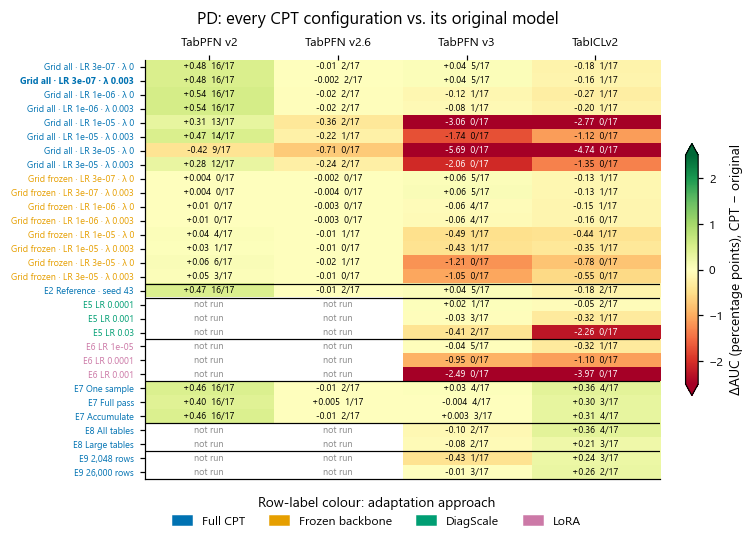

PD. Held-out credit tables, final five-fold benchmark. Each cell is the equal-table mean change in AUC (percentage points) of an adapted model relative to the original checkpoint of the same base, followed by the number of tables that improved by more than 0.1 pp and the number of complete tables. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Rows are grouped by experiment (E1 main grid: four learning rates × L2-SP λ ∈ {0, 0.003} × all or frozen-backbone updates; E2 the reference recipe with a second training seed; E3 sampling protocols; E5 DiagScale query-scaling adapters; E6 all versus large training tables; E7 episode sizes on the large-table corpus; E8 rank-16 query/value LoRA). The bold row is the predefined reference recipe (full updates, LR 3e-7, λ 0.003); every other row is reported in full rather than selected. Label colours identify the adaptation approach. Colours are symmetric about zero and saturate at the 95th percentile of |cell value| (2.51); printed values are exact. 'Not run' marks base/approach combinations outside a study's design. Studies differ in more than their named factor (see the comparability table).

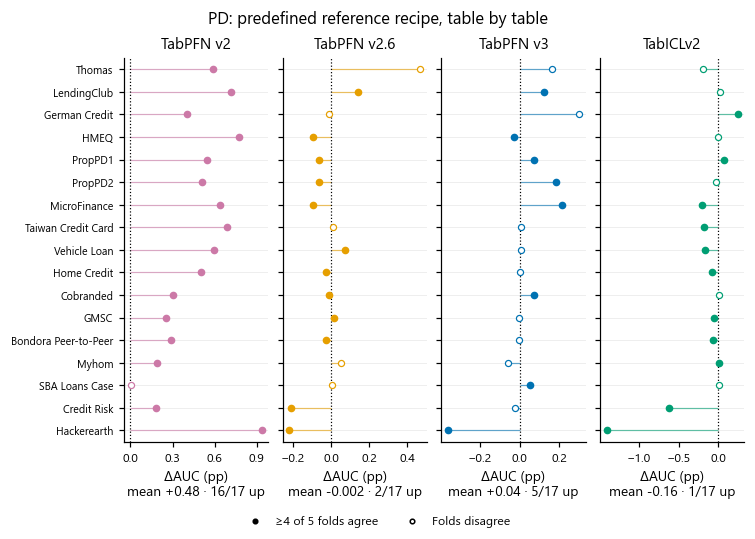

PD. Experiment 1, predefined reference recipe (all trainable weights updated, peak LR 3e-7, L2-SP λ 0.003, seed 42), final five-fold benchmark: paired change in AUC (percentage points) on every held-out credit table relative to the original model of the same base. Each axis label gives the equal-table mean and the number of tables improving by more than 0.1 pp. Filled markers: at least four of the five outer folds change in the direction of the table mean; open markers: the folds disagree. Tables are ordered by their mean effect across the four bases; horizontal axes differ between models. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. 

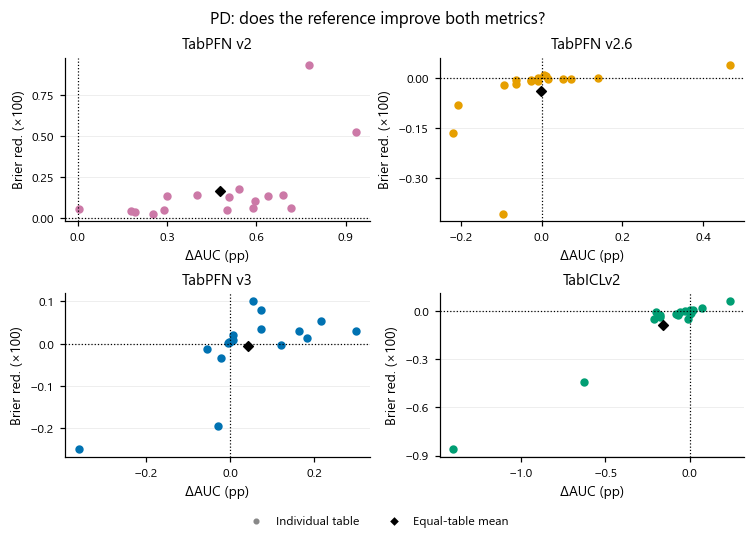

PD. The predefined full-update reference (peak LR 3e-7, L2-SP 0.003, seed 42) on held-out credit tables. Horizontal values are ΔAUC (percentage points); vertical values are Brier reduction (×100). Each colored point represents one table with five complete paired outer folds for both metrics; the diamond is their equal-table mean. Both directions are oriented so that positive favors CPT. Axis ranges differ by base to retain small effects. AUC measures ranking; Brier score measures probability error, so their changes need not agree. 

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabICLv2,roc_auc,17,0.797067,0.792619,-0.004448,...,-0.004292,0.000054,-0.035491,0.001229,1,5,11,21,85,0.058824
1,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v2,roc_auc,17,0.778915,0.779312,0.000397,...,0.000011,0.000946,-0.002281,0.001725,4,12,1,55,85,0.235294
2,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v2.6,roc_auc,17,0.792242,0.792135,-0.000107,...,-0.000282,-0.000042,-0.000702,0.001103,1,16,0,21,85,0.058824
3,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v3,roc_auc,17,0.798170,0.793301,-0.004868,...,-0.007981,-0.000676,-0.018535,0.002261,1,4,12,11,85,0.058824
4,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0.003,TabICLv2,roc_auc,17,0.797067,0.793530,-0.003537,...,-0.003437,0.000244,-0.026367,0.001438,1,5,11,23,85,0.058824
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8,LoRA,LoRA,E6 LR 0.0001,TabPFN v3,roc_auc,17,0.798177,0.788666,-0.009511,...,-0.010384,-0.002682,-0.040906,-0.001182,0,0,17,8,85,0.000000
96,8,LoRA,LoRA,E6 LR 0.001,TabICLv2,roc_auc,17,0.797067,0.757412,-0.039655,...,-0.047462,-0.020130,-0.158151,-0.001812,0,0,17,3,85,0.000000
97,8,LoRA,LoRA,E6 LR 0.001,TabPFN v3,roc_auc,17,0.798177,0.773259,-0.024917,...,-0.029129,-0.005759,-0.135683,-0.000960,0,1,16,2,85,0.000000
98,8,LoRA,LoRA,E6 LR 1e-05,TabICLv2,roc_auc,17,0.797067,0.793830,-0.003237,...,-0.002792,-0.000133,-0.025232,0.003325,1,7,9,17,85,0.058824


In [3]:
cp.show(sink, sy.plot_landscape(credit, TRACK), track=TRACK)
cp.show(sink, sy.plot_reference_tables(credit, TRACK), track=TRACK)
cp.show(sink, rv.plot_secondary_effects(credit, secondary, TRACK), track=TRACK)
report.table('Every configuration: original, CPT, paired effect and consistency', sy.summarize(credit))
report.add('2. RQ1: when does domain CPT help?', sy.findings(credit, TRACK))

## 3. RQ1: learning rate and the extra training seed

Experiment 1 varies learning rate with full updates and L2-SP 0.003. Experiment 2 repeats the predefined reference with seed 43. The two seeds are a limited stability check; they do not establish a training-variance distribution. The remaining factorial cells are retained in the next section.

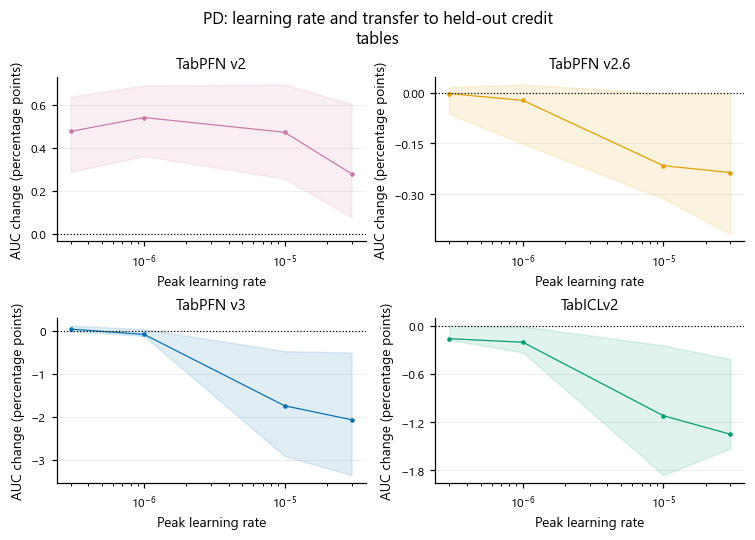

PD. AUC change (percentage points) after 10,000 successful updates, relative to the same original model, on held-out credit tables. All parameters are updated with L2-SP 0.003. Lines show equal-table means; shading is the interquartile range of table effects, not confidence intervals. All learning rates use the same complete table cohort within each base. Positive values favor CPT. Experiments 3 and 4 retain the remaining cells of the shared 512-run factorial and its anchoring/freezing interaction.

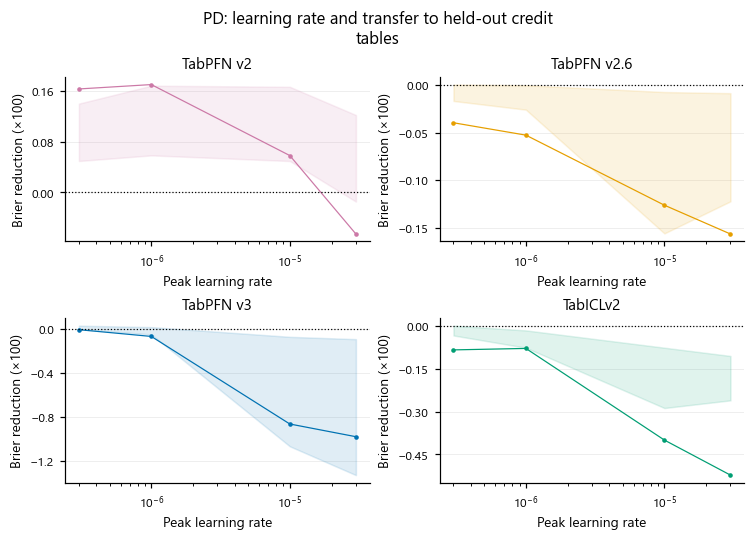

PD. Brier reduction (×100) after 10,000 successful updates, relative to the same original model, on held-out credit tables. All parameters are updated with L2-SP 0.003. Lines show equal-table means; shading is the interquartile range of table effects, not confidence intervals. All learning rates use the same complete table cohort within each base. Positive values favor CPT. Experiments 3 and 4 retain the remaining cells of the shared 512-run factorial and its anchoring/freezing interaction.

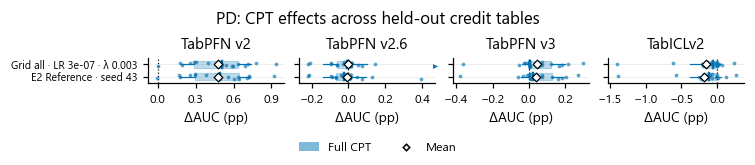

PD. Distribution over held-out credit tables of the paired change in AUC (percentage points) relative to each base's original model. Boxes span the table interquartile range, the thick line is the median, whiskers reach the 10th and 90th percentiles, dots are individual tables and the white diamond is the equal-table mean. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Experiment 1 contributes only its predefined reference recipe (LR 3e-7, L2-SP λ 0.003) with all parameters updated and with the backbone frozen; every follow-up contributes all prescribed arms, so no row is chosen by its outcome. Horizontal axes differ between models and span each model's 2nd-98th percentile of table effects and zero; tables outside that range are drawn as triangles at the axis edge (TabPFN v2: 0, TabPFN v2.6: 1, TabPFN v3: 0, TabICLv2: 0 tables) and keep their exact values in the summary. Spread describes heterogeneity across tables, not statistical uncertainty.

In [4]:
main_run = next(run for campaign, arm, run in studies if campaign == 1)
factorial = ce.benchmark_grid(main_run)
cp.show(sink, rv.plot_learning_rates(factorial, TRACK), track=TRACK)
seed_values = credit[credit.reference | credit.experiment.eq(2)]
cp.show(sink, sy.plot_distributions(seed_values, TRACK), track=TRACK)
report.add('3. RQ1: learning rate and the extra training seed', 'Reference seed 42 and seed 43 use identical evaluation folds. Learning-rate curves fix table cohorts across all rates; their shading is table heterogeneity, not confidence intervals.')

## 4. RQ2: anchoring, freezing and adapter recipes

The complete full/frozen × unanchored/anchored factorial is retained. The two anchoring contrasts and their interaction show why freezing and L2-SP cannot be treated as independent switches. All freezing contrasts are also printed. DiagScale and LoRA are separate recipe evaluations; differences in their sampling, episode sizes, training precision and regularization prevent an intrinsic adapter ranking.

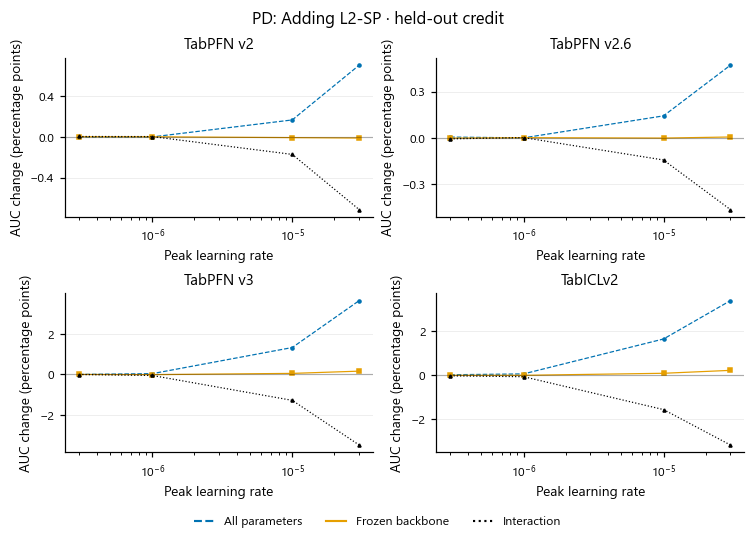

PD. Adding L2-SP in the shared factorial, evaluated on held-out credit tables. Every contrast pairs the same table, base, rate and sampling recipe and requires all four full/frozen × unanchored/anchored cells. The dotted interaction is (anchored minus unanchored under freezing) minus the same contrast under full updates. Five row folds are averaged within table before equal-table means; table cohorts stay fixed across learning rates. Positive simple effects favor the changed choice; a positive interaction means anchoring helps more under freezing, not necessarily positive transfer. These are two analyses of the same 512 unique training runs; no extra independent replications are implied.

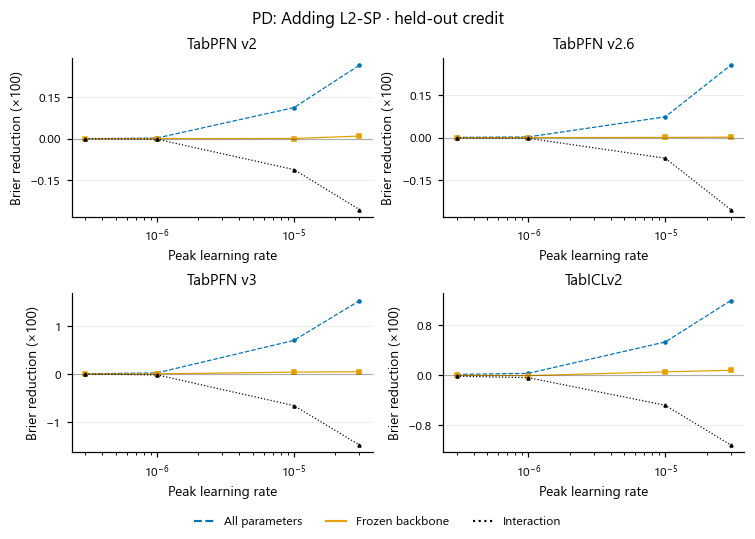

PD. Adding L2-SP in the shared factorial, evaluated on held-out credit tables. Every contrast pairs the same table, base, rate and sampling recipe and requires all four full/frozen × unanchored/anchored cells. The dotted interaction is (anchored minus unanchored under freezing) minus the same contrast under full updates. Five row folds are averaged within table before equal-table means; table cohorts stay fixed across learning rates. Positive simple effects favor the changed choice; a positive interaction means anchoring helps more under freezing, not necessarily positive transfer. These are two analyses of the same 512 unique training runs; no extra independent replications are implied.

,domain,metric,base,dataset,learning_rate,sampling,contrast,condition
0,credit,brier_score,TabICLv2,Bondora Peer-to-Peer,3.000000e-07,one_sample,0.000352,L2-SP off
1,credit,brier_score,TabICLv2,Bondora Peer-to-Peer,1.000000e-06,one_sample,0.000893,L2-SP off
2,credit,brier_score,TabICLv2,Bondora Peer-to-Peer,1.000000e-05,one_sample,0.003273,L2-SP off
3,credit,brier_score,TabICLv2,Bondora Peer-to-Peer,3.000000e-05,one_sample,0.017627,L2-SP off
4,credit,brier_score,TabICLv2,Cobranded,3.000000e-07,one_sample,0.000059,L2-SP off
...,...,...,...,...,...,...,...,...
3019,ood,roc_auc,TabPFN v3,openml_46952,3.000000e-05,one_sample,-0.021554,Interaction
3020,ood,roc_auc,TabPFN v3,openml_46956,3.000000e-07,one_sample,-0.000113,Interaction
3021,ood,roc_auc,TabPFN v3,openml_46956,1.000000e-06,one_sample,-0.004550,Interaction
3022,ood,roc_auc,TabPFN v3,openml_46956,1.000000e-05,one_sample,-0.047101,Interaction


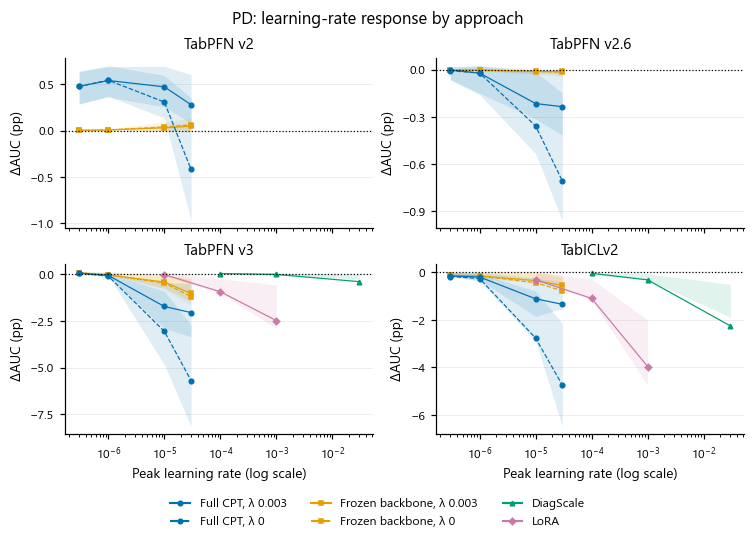

PD. Equal-table mean paired change in AUC (percentage points) relative to the original model, against peak learning rate, for full-parameter and frozen-backbone CPT (experiment 1; solid λ = 0.003, dashed λ = 0), DiagScale query-scaling adapters (experiment 5) and query/value LoRA (experiment 6). Shaded bands span the table interquartile range, not confidence intervals. Each curve retains the same complete table cohort across its rates. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. The rate scales are not interchangeable across approaches: DiagScale updates multiplicative query scales and LoRA updates low-rank factors, so their rates are shown on a common axis only to display each approach's own sensitivity. The studies also differ in PD sampling, training precision and TabICLv2 inference settings.

In [5]:
cp.show(sink, rv.plot_factorial(factorial, TRACK, 3), track=TRACK)
report.table('Freezing effects at both L2-SP levels and the interaction', rv.factorial_contrasts(factorial, 4))
cp.show(sink, sy.plot_rate_response(credit, TRACK), track=TRACK)
report.add('4. RQ2: anchoring, freezing and adapter recipes', 'Every factorial contrast requires all four matched cells. Positive choice effects can mean less damage, not positive transfer. The same 512 unique runs support experiments 1, 3 and 4.')

## 5. RQ3: exposure, training corpus and episode size

Experiment 7 changes row exposure and update weighting at the same successful-update budget. Experiments 8 and 9 separate training-corpus composition from episode size; the original held-out partitions stay fixed. The 8,192-row large-corpus control is reused, not trained or counted again. Equal updates do not imply equal rows, FLOPs or wall time.

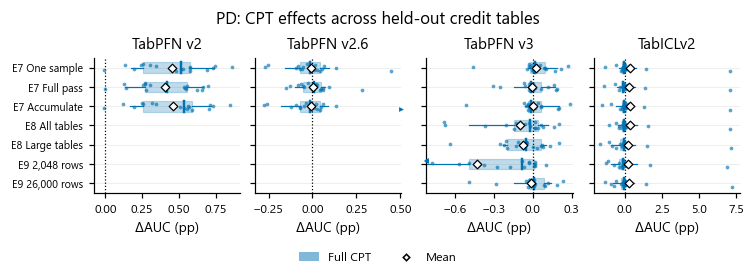

PD. Distribution over held-out credit tables of the paired change in AUC (percentage points) relative to each base's original model. Boxes span the table interquartile range, the thick line is the median, whiskers reach the 10th and 90th percentiles, dots are individual tables and the white diamond is the equal-table mean. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Experiment 1 contributes only its predefined reference recipe (LR 3e-7, L2-SP λ 0.003) with all parameters updated and with the backbone frozen; every follow-up contributes all prescribed arms, so no row is chosen by its outcome. Horizontal axes differ between models and span each model's 2nd-98th percentile of table effects and zero; tables outside that range are drawn as triangles at the axis edge (TabPFN v2: 0, TabPFN v2.6: 1, TabPFN v3: 2, TabICLv2: 0 tables) and keep their exact values in the summary. Spread describes heterogeneity across tables, not statistical uncertainty.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,3,Sampling,Full CPT,E7 Accumulate,TabICLv2,brier_score,17,0.120268,0.113720,0.006548,...,-0.000311,0.000029,-0.009884,0.112919,4,5,8,28,85,0.235294
1,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2,brier_score,17,0.118123,0.116673,0.001450,...,0.000436,0.001309,-0.000020,0.008482,16,1,0,75,85,0.941176
2,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2.6,brier_score,17,0.113695,0.114104,-0.000409,...,-0.000182,0.000009,-0.003419,0.000457,1,8,8,18,85,0.058824
3,3,Sampling,Full CPT,E7 Accumulate,TabPFN v3,brier_score,17,0.111857,0.112203,-0.000345,...,-0.000096,0.000216,-0.004258,0.000770,7,6,4,45,85,0.411765
4,3,Sampling,Full CPT,E7 Full pass,TabICLv2,brier_score,17,0.120268,0.113885,0.006383,...,-0.000579,0.000043,-0.009607,0.112812,4,2,11,26,85,0.235294
5,3,Sampling,Full CPT,E7 Full pass,TabPFN v2,brier_score,17,0.118123,0.117013,0.001110,...,0.000390,0.001290,-0.000007,0.004345,16,1,0,76,85,0.941176
6,3,Sampling,Full CPT,E7 Full pass,TabPFN v2.6,brier_score,17,0.113695,0.113920,-0.000225,...,-0.000152,0.000043,-0.002692,0.000314,2,9,6,28,85,0.117647
7,3,Sampling,Full CPT,E7 Full pass,TabPFN v3,brier_score,17,0.111857,0.112059,-0.000202,...,-0.000171,0.000091,-0.002772,0.001668,4,8,5,33,85,0.235294
8,3,Sampling,Full CPT,E7 One sample,TabICLv2,brier_score,17,0.120268,0.113531,0.006737,...,-0.000249,0.000053,-0.008277,0.112859,3,5,9,30,85,0.176471
9,3,Sampling,Full CPT,E7 One sample,TabPFN v2,brier_score,17,0.118123,0.116643,0.001481,...,0.000424,0.001300,0.000106,0.008810,17,0,0,76,85,1.000000


In [6]:
exposure = credit[credit.experiment.isin([3, 6, 7])]
cp.show(sink, sy.plot_distributions(exposure, TRACK), track=TRACK)
report.table('Exposure/corpus/episode effects on the secondary metric', sy.summarize(secondary[secondary.experiment.isin([3, 6, 7])]))
report.add('5. RQ3: exposure, training corpus and episode size', 'All available prescribed arms are shown. Corpus and episode comparisons are PD-only; LGD contains the sampling comparison. Native training ceilings differ by model.')

## 6. Transfer, retention and table heterogeneity

The four same-task non-credit tables provide a bounded retention check. Each table averages all four training partitions before the equal-table mean. They do not establish universal out-of-domain safety. The outcome bands below describe effect size, not statistical significance.

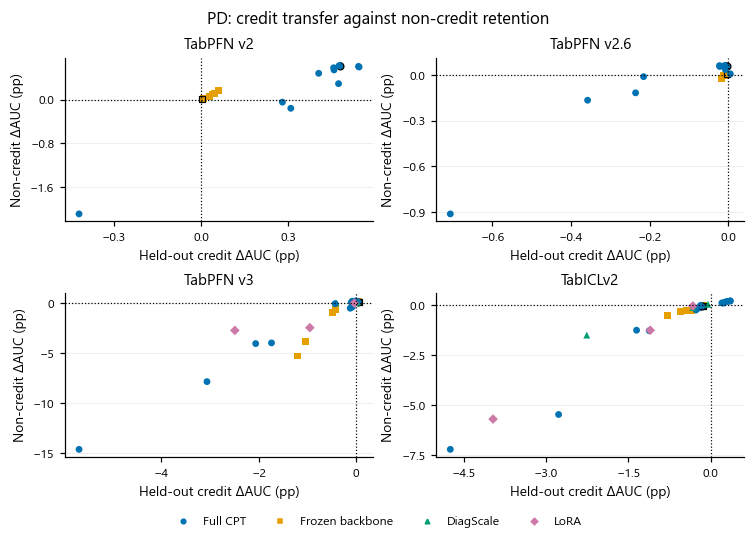

PD. Each point is one configuration: its equal-table mean paired change on held-out credit tables (horizontal) and on the four non-credit retention tables of the same task (vertical), both relative to the original model of the same base. Non-credit tables first average all four CPT training partitions. The upper-right quadrant improves both; the lower-right gains on credit while losing on the retention panel. Points outlined in black are the experiment-1 reference recipes (full and frozen). Axis limits differ between models. A four-table retention panel does not establish general retention. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. 

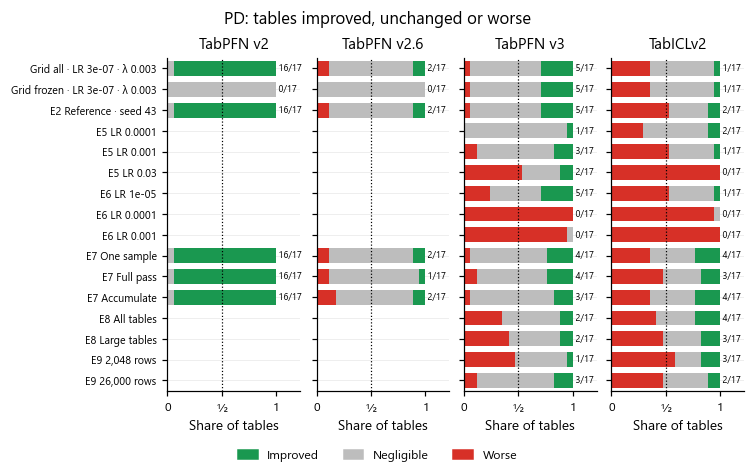

PD. For the same arms as the distribution figure, the share of held-out credit tables whose paired AUC change relative to the original model exceeds +0.1 percentage points (improved), lies within ±0.1 (negligible) or falls below −0.1 (worse); numbers give improved/total tables. The ±0.1 band is a reporting convention for this study, not a statistical equivalence margin. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. The dotted line marks half of the tables.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabICLv2,roc_auc,4,0.874683,0.871854,-0.002828,...,-0.003824,-0.000049,-0.009674,0.000451,0,2,2,21,80,0.00
1,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v2,roc_auc,4,0.848628,0.849670,0.001042,...,0.000391,0.001624,0.000056,0.002168,2,2,0,62,80,0.50
2,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v2.6,roc_auc,4,0.871975,0.871927,-0.000048,...,-0.000178,0.000206,-0.000586,0.000241,0,4,0,34,80,0.00
3,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v3,roc_auc,4,0.872980,0.863178,-0.009802,...,-0.011333,-0.002036,-0.031337,-0.000736,0,1,3,14,80,0.00
4,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0.003,TabICLv2,roc_auc,4,0.874683,0.871951,-0.002732,...,-0.003583,-0.000114,-0.009145,0.000146,0,2,2,25,80,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8,LoRA,LoRA,E6 LR 0.0001,TabPFN v3,roc_auc,4,0.872980,0.848413,-0.024566,...,-0.037825,-0.002209,-0.066927,-0.000405,0,1,3,10,80,0.00
96,8,LoRA,LoRA,E6 LR 0.001,TabICLv2,roc_auc,4,0.874683,0.817568,-0.057115,...,-0.078950,-0.016556,-0.143197,-0.008479,0,0,4,5,80,0.00
97,8,LoRA,LoRA,E6 LR 0.001,TabPFN v3,roc_auc,4,0.872980,0.845662,-0.027318,...,-0.031722,-0.019818,-0.053757,-0.007070,0,0,4,2,80,0.00
98,8,LoRA,LoRA,E6 LR 1e-05,TabICLv2,roc_auc,4,0.874683,0.874051,-0.000631,...,-0.001898,0.000797,-0.003190,0.001603,1,1,2,34,80,0.25


In [7]:
cp.show(sink, sy.plot_transfer_retention(credit, retention, TRACK), track=TRACK)
cp.show(sink, sy.plot_outcomes(credit, TRACK), track=TRACK)
report.table('Non-credit retention per configuration', sy.summarize(retention))
report.add('6. Transfer, retention and table heterogeneity', 'Positive means CPT improves its own original baseline. Negligible bands are descriptive reporting thresholds: ' + str(style.TIE_BAND[sy.PRIMARY[TRACK]]) + ' on the native metric scale.')

## 7. RQ4: the amount of labeled target context

Original and CPT absolute performance are shown beside their paired difference on both task metrics. The overview uses the cohort supporting every nominal context size through 2,048 rows; experiment 10 contains the other horizons and individually named table curves. All five-fold test rows stay fixed while context shrinks. The unchanged inner validation set is an additional label budget.

,setting,value
0,Models,Explicit TabPFN v3 and TabICLv2 original/CPT p...
1,CPT source,cpt_main_v5; full updates; LR 3e-07; L2-SP 0.0...
2,Dataset exclusion,Each table uses its original experiment-1 held...
3,Outer test folds,5
4,Context rows,"8, 12, 16, 24, 32, 48, 64, 96, 128, 192, 256, ..."
5,Additional endpoint,"Available context pool, capped at 50,000, with..."
6,Validation labels,"Fixed 20% of each outer training fold, separat..."
7,Test rows,All outer-test rows; unchanged across context ...
8,Inference views,"{'tabpfn': 32, 'tabicl': 8}"
9,TabICL inference,automatic; precision sensitivity caveat applies


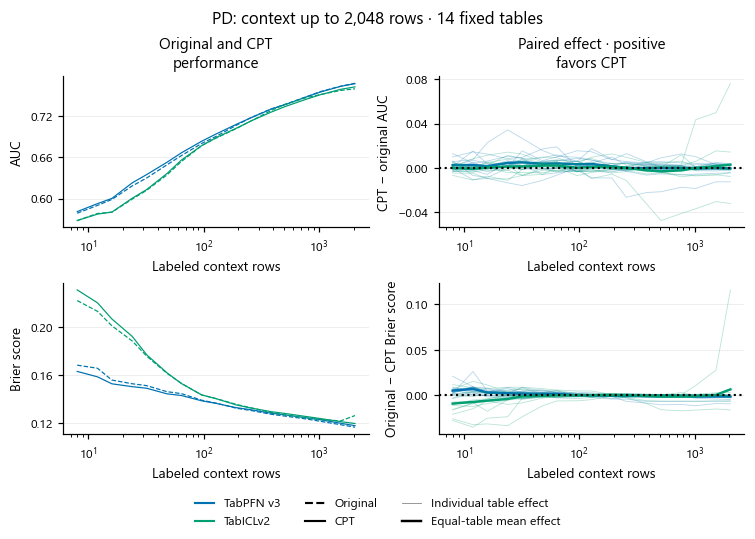

PD. Original and fixed-recipe CPT AUC and Brier score (left), with their paired effects (right). The same 14 tables contribute at every displayed context size and to every displayed model. Scores are averaged over five paired outer folds within table, then equally across tables. Thin colored curves retain individual table effects; thick curves show their equal-table mean. These curves are not uncertainty bands or repeated-context variance estimates. Validation labels have a fixed additional budget; all outer-test rows are unchanged. The horizon identifies the table cohort, so levels across different horizon panels need not agree. The CPT checkpoint is the experiment-1 reference recipe (full updates, LR 3e-7, L2-SP 0.003) whose training partition excluded the table; positive differences favour CPT.

In [8]:
study = cc.load_context_study()
report.table('Context protocol and actual inference policy', cc.protocol_table(study))
cp.show(sink, cc.plot_context_curves(study, selected_track=TRACK, horizons=(2048,)), track=TRACK)
report.add('7. RQ4: the amount of labeled target context', 'Both metrics and every displayed model use the same table cohort throughout each curve. Thin curves show individual table effects; thick curves show equal-table means. Different cohort horizons must not be joined as one curve. Experiment 10 includes the separately gated v2/v2.6 extension when available.')

## 8. Which tables move, and what does adaptation cost?

The table maps retain named tables and outcome-independent arms. Training cost is measured over the four dataset partitions and excludes queueing and evaluation. These historical measurements do not form a controlled compute-matched comparison.

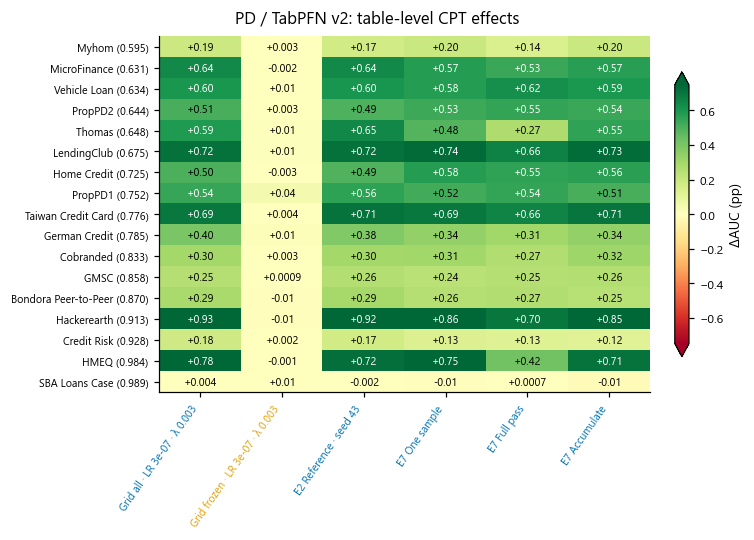

PD. TabPFN v2, held-out credit tables: paired change in AUC (percentage points) of each study arm relative to the original model (panel 1 of 1). Rows are tables, ordered by the original model's mean score (in parentheses, averaged over the available original evaluations; inference recipes can differ across studies); columns are the outcome-independent arms of the distribution figure, coloured by approach. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. All panels for this base share a colour scale, symmetric about zero and saturated at the 95th percentile of |value| (0.75); labels give rounded values. '—' marks a missing complete comparison.

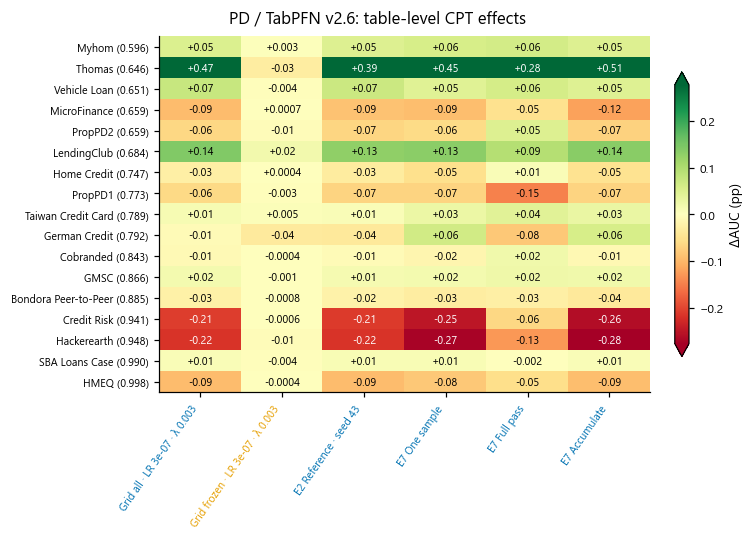

PD. TabPFN v2.6, held-out credit tables: paired change in AUC (percentage points) of each study arm relative to the original model (panel 1 of 1). Rows are tables, ordered by the original model's mean score (in parentheses, averaged over the available original evaluations; inference recipes can differ across studies); columns are the outcome-independent arms of the distribution figure, coloured by approach. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. All panels for this base share a colour scale, symmetric about zero and saturated at the 95th percentile of |value| (0.28); labels give rounded values. '—' marks a missing complete comparison.

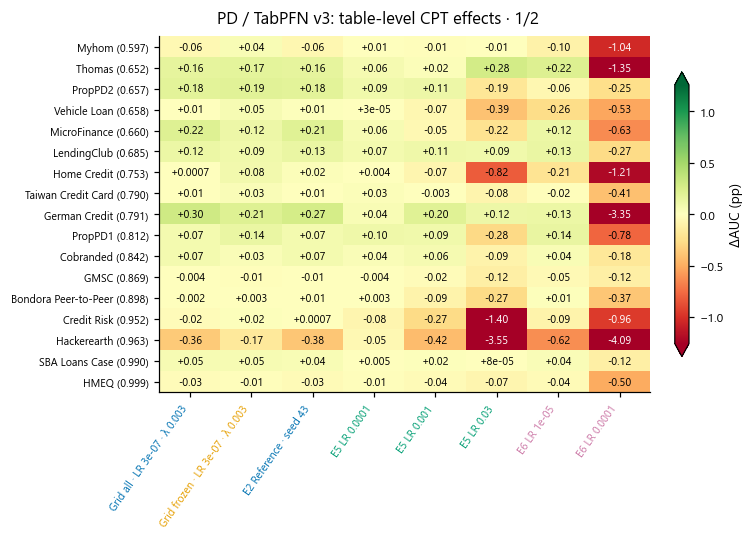

PD. TabPFN v3, held-out credit tables: paired change in AUC (percentage points) of each study arm relative to the original model (panel 1 of 2). Rows are tables, ordered by the original model's mean score (in parentheses, averaged over the available original evaluations; inference recipes can differ across studies); columns are the outcome-independent arms of the distribution figure, coloured by approach. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. All panels for this base share a colour scale, symmetric about zero and saturated at the 95th percentile of |value| (1.26); labels give rounded values. '—' marks a missing complete comparison.

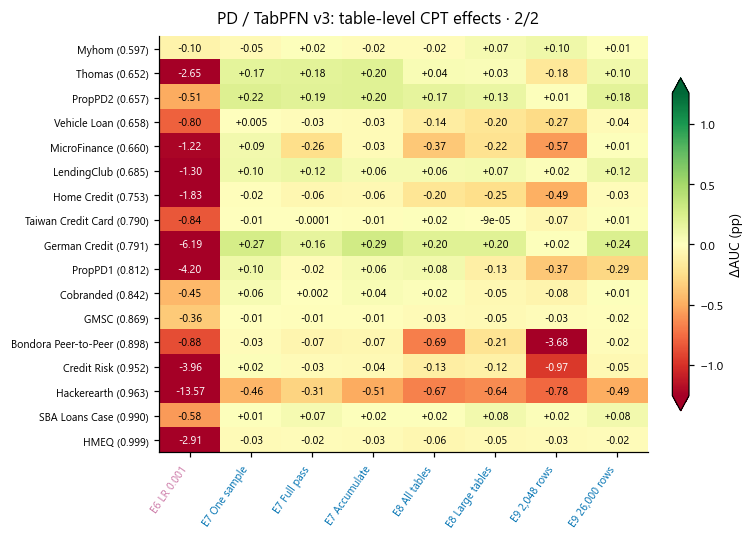

PD. TabPFN v3, held-out credit tables: paired change in AUC (percentage points) of each study arm relative to the original model (panel 2 of 2). Rows are tables, ordered by the original model's mean score (in parentheses, averaged over the available original evaluations; inference recipes can differ across studies); columns are the outcome-independent arms of the distribution figure, coloured by approach. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. All panels for this base share a colour scale, symmetric about zero and saturated at the 95th percentile of |value| (1.26); labels give rounded values. '—' marks a missing complete comparison.

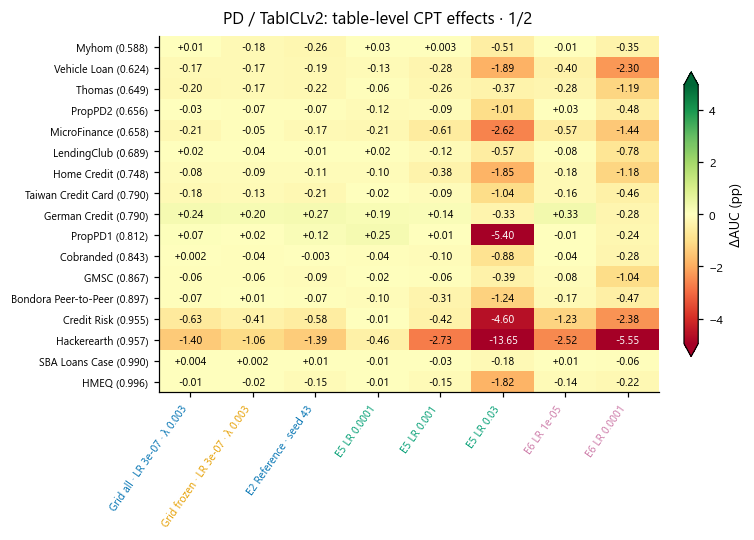

PD. TabICLv2, held-out credit tables: paired change in AUC (percentage points) of each study arm relative to the original model (panel 1 of 2). Rows are tables, ordered by the original model's mean score (in parentheses, averaged over the available original evaluations; inference recipes can differ across studies); columns are the outcome-independent arms of the distribution figure, coloured by approach. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. All panels for this base share a colour scale, symmetric about zero and saturated at the 95th percentile of |value| (4.96); labels give rounded values. '—' marks a missing complete comparison.

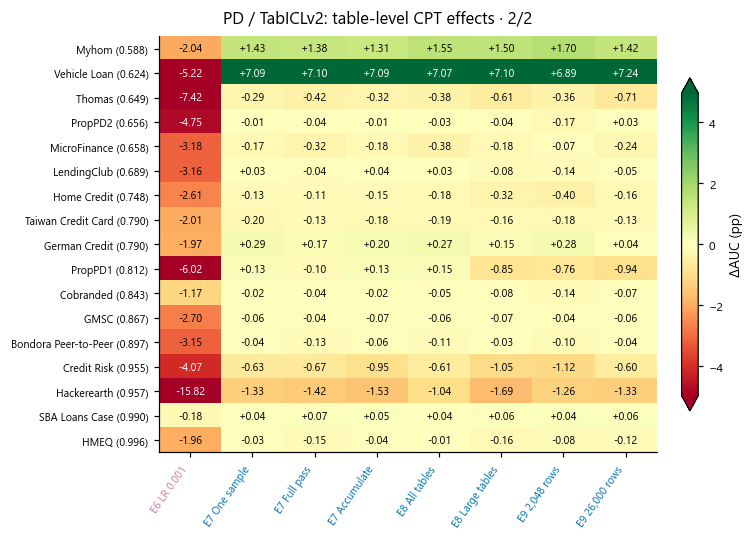

PD. TabICLv2, held-out credit tables: paired change in AUC (percentage points) of each study arm relative to the original model (panel 2 of 2). Rows are tables, ordered by the original model's mean score (in parentheses, averaged over the available original evaluations; inference recipes can differ across studies); columns are the outcome-independent arms of the distribution figure, coloured by approach. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. All panels for this base share a colour scale, symmetric about zero and saturated at the 95th percentile of |value| (4.96); labels give rounded values. '—' marks a missing complete comparison.

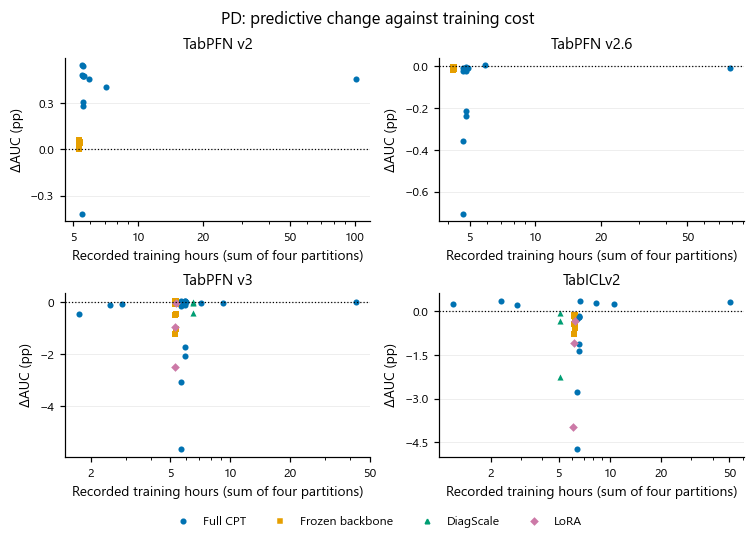

PD. Each point is one configuration: its equal-table mean paired change in AUC (percentage points) on held-out credit tables against recorded training time summed over the four CPT partitions (logarithmic axis). Training time excludes evaluation and queueing and was recorded on the GPUs used for each study, so it is an observed cost, not a matched-compute comparison. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. 

In [9]:
for base in sy.BASES:
    cp.show(sink, sy.plot_table_map(credit, TRACK, base), track=TRACK)
cp.show(sink, sy.plot_cost_effect(credit, sy.costs(studies), TRACK), track=TRACK)
report.add('8. Which tables move, and what does adaptation cost?', 'Original baselines can differ with inference recipes; each effect remains paired within its own study. Absolute secondary-metric scores are retained in the final summary.')

## 9. What can be concluded, and what remains exploratory?

The predefined reference is the interpretable starting point. The best observed recipe is selected on these results and is optimistic. Leaving one table out of recipe selection is a retrospective sensitivity analysis conditional on the fitted grid, not nested validation of a new-table selection procedure. The later model-coverage extension is also exploratory.

In [10]:
report.table('Highest, lowest and most consistent observed configuration per base', sy.extremes(sy.summarize(credit)))
report.table('Predefined reference and retrospective selection sensitivity', sy.selection_check(credit[credit.experiment.eq(1)]))
report.table('Secondary metric: all original/CPT scores and paired effects', sy.summarize(secondary))
report.add('9. What can be concluded, and what remains exploratory?', 'State model-, task- and recipe-dependent transfer rather than uniform success or failure. Check precision comparability before cross-study claims. Neither two training seeds nor nested single context subsets identify a full bias–variance decomposition. Do not count reused factorial or 8,192-row controls as independent evidence.')

,base,role,configuration,mean,median,improved,negligible,worse,tables
0,TabICLv2,Highest observed mean,E7 One sample,0.003603,-0.000316,4,7,6,17
1,TabICLv2,Lowest observed mean,Grid all · LR 3e-05 · λ 0,-0.047446,-0.038239,0,0,17,17
2,TabICLv2,Most tables improved,E7 One sample,0.003603,-0.000316,4,7,6,17
3,TabPFN v2,Highest observed mean,Grid all · LR 1e-06 · λ 0,0.005437,0.005413,16,1,0,17
4,TabPFN v2,Lowest observed mean,Grid all · LR 3e-05 · λ 0,-0.004190,0.001455,9,3,5,17
5,TabPFN v2,Most tables improved,Grid all · LR 1e-06 · λ 0,0.005437,0.005413,16,1,0,17
6,TabPFN v2.6,Highest observed mean,E7 Full pass,0.000049,0.000073,1,14,2,17
7,TabPFN v2.6,Lowest observed mean,Grid all · LR 3e-05 · λ 0,-0.007067,-0.004303,0,2,15,17
8,TabPFN v2.6,Most tables improved,Grid all · LR 1e-06 · λ 0.003,-0.000225,-0.000079,2,9,6,17
9,TabPFN v3,Highest observed mean,Grid frozen · LR 3e-07 · λ 0.003,0.000603,0.000495,5,11,1,17


,base,tables,recipes,reference_recipe,reference_mean,best_observed_recipe,best_observed_mean,leave_one_table_out_mean,leave_one_table_out_improved,recipes_chosen
0,TabICLv2,17,16,Grid all · LR 3e-07 · λ 0.003,-0.001581,Grid frozen · LR 3e-07 · λ 0,-0.001310,-0.001730,3,"Grid frozen · LR 3e-07 · λ 0 ×15, Grid frozen ..."
1,TabPFN v2,17,16,Grid all · LR 3e-07 · λ 0.003,0.004773,Grid all · LR 1e-06 · λ 0,0.005437,0.005437,17,Grid all · LR 1e-06 · λ 0 ×17
2,TabPFN v2.6,17,16,Grid all · LR 3e-07 · λ 0.003,-0.000024,Grid frozen · LR 3e-07 · λ 0,-0.000016,-0.000488,2,"Grid all · LR 3e-07 · λ 0.003 ×8, Grid frozen ..."
3,TabPFN v3,17,16,Grid all · LR 3e-07 · λ 0.003,0.000430,Grid frozen · LR 3e-07 · λ 0.003,0.000603,0.000603,14,Grid frozen · LR 3e-07 · λ 0.003 ×17


,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabICLv2,brier_score,17,0.112620,0.115040,-0.002420,...,-0.001339,-0.000116,-0.023933,0.000192,3,1,13,22,85,0.176471
1,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v2,brier_score,17,0.118123,0.118112,0.000011,...,-0.000159,0.000187,-0.001249,0.001395,7,3,7,35,85,0.411765
2,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v2.6,brier_score,17,0.113695,0.113737,-0.000042,...,-0.000069,0.000044,-0.000441,0.000193,2,11,4,36,85,0.117647
3,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v3,brier_score,17,0.111856,0.114078,-0.002222,...,-0.002976,-0.000342,-0.015627,0.000338,1,2,14,12,85,0.058824
4,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0.003,TabICLv2,brier_score,17,0.112620,0.114478,-0.001859,...,-0.000748,-0.000102,-0.019105,0.000216,3,1,13,18,85,0.176471
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8,LoRA,LoRA,E6 LR 0.0001,TabPFN v3,brier_score,17,0.111856,0.116905,-0.005049,...,-0.004431,-0.000604,-0.030415,0.000085,0,1,16,9,85,0.000000
96,8,LoRA,LoRA,E6 LR 0.001,TabICLv2,brier_score,17,0.112620,0.126934,-0.014314,...,-0.018515,-0.004757,-0.073268,-0.001342,0,0,17,1,85,0.000000
97,8,LoRA,LoRA,E6 LR 0.001,TabPFN v3,brier_score,17,0.111856,0.123470,-0.011614,...,-0.009543,-0.001137,-0.069155,-0.000215,0,0,17,1,85,0.000000
98,8,LoRA,LoRA,E6 LR 1e-05,TabICLv2,brier_score,17,0.112620,0.114662,-0.002042,...,-0.000626,-0.000072,-0.019691,0.000238,1,4,12,14,85,0.058824


## Complete text summary

Every displayed table, plotted value and caption, in section order.

In [11]:
print(report.summary(sink))

Overview: domain continued pretraining for PD

0. Evidence and interpretation
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Five-fold final benchmarks; equal-table paired effects; missing evidence remains explicit.

1. Design, unique runs and comparability
Experiment 0 (controls and pilots) is excluded. Each study pairs its adapted checkpoints with its own evaluation of the original model, under that study's inference settings, so every effect in this notebook is a within-study paired difference. Grid labels refer to the shared 512-run factorial analyzed by experiments 1, 3 and 4; each unique checkpoint enters the catalog once. The TabPFN v2/TabPFN v2.6 additions extend model coverage and remain explicitly exploratory. Experiment 10 reuses the predefined main-grid reference checkpoints at varying context sizes. Experiments 8 and 9 are PD-only. Cross-study contrasts can invo